In [1]:
# Внимание!!! Важно, что бы файлы с данными и исполняемый файл находились в одной папке, 
# тогда пути к тестовым и тренировочным наборам будут содержать только имена файлов.
# 
# В пути к тренировочным и тестовым данным запрежается использовать абсалютную адресацию, 
# то есть адресацию, в которой присутствуют имена папок. Путь должен содержать только имя файла.
#
# Напоминание: под моделью машинного обучения понимаются все действия с исходными данными, 
# которые необходимо произвести, что бы сопоставить признаки целевому значению.

### Область работы 1 (библиотеки)

In [53]:
# Данный блок в области 1 НЕ выполняется преподавателем
# 
# данный блок предназначен только для подключения необходимых библиотек
# запрещается подключать библиотеки в других блоках
#
# установка дополнительных библиотек размещается прямо здесь (обязательно закоментированы)
#
# pip install

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, StratifiedShuffleSplit, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier, StackingClassifier, VotingClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import fbeta_score, f1_score, classification_report, make_scorer, roc_curve, roc_auc_score



### Область работы 2 (поиск  модели .... )

In [7]:
# Данный блок(и) НЕ выполняются преподавателем в области 2
# блок(и) предназначены для поиска лучшей модели 
# должен быть понятен и очевиден отбор параметров модели
# 
# Запрещается размещать данные блоки за пределами обасти 2
# Все блоки данной области должны быть выполнены
#
# ЗАПРЕЩАЕТСЯ ИСПОЛЬЗОВАТЬ ТЕСТОВЫЙ НАБОР
#
# Путь к тренировочному набору
# 

path_train = 'train.csv' # содержит только имя файла, без имен папок !!!
path_train_Y = 'train_Y.csv' # содержит только имя файла, без имен папок !!!

In [9]:
df = pd.read_csv(path_train)
train_Y = pd.read_csv(path_train_Y)
df['Diabetes_binary'] = train_Y
df




,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,0.0,0.0,1.0,23.0,1.0,0.0,1.0,1.0,1.0,0.0,...,0.0,4.0,5.0,2.0,0.0,0.0,6.0,6.0,3.0,1.0
1,1.0,1.0,1.0,35.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,4.0,15.0,15.0,0.0,0.0,10.0,4.0,5.0,1.0
2,1.0,0.0,1.0,30.0,1.0,1.0,0.0,0.0,1.0,1.0,...,0.0,3.0,30.0,30.0,0.0,0.0,4.0,5.0,1.0,1.0
3,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,1.0,8.0,6.0,7.0,1.0
4,0.0,0.0,1.0,36.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,3.0,0.0,2.0,0.0,0.0,5.0,4.0,5.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47358,1.0,1.0,1.0,27.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,1.0,13.0,5.0,6.0,1.0
47359,0.0,1.0,1.0,31.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,2.0,0.0,1.0,0.0,1.0,9.0,6.0,8.0,0.0
47360,1.0,0.0,1.0,28.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,4.0,5.0,20.0,0.0,0.0,9.0,4.0,6.0,1.0
47361,0.0,0.0,1.0,25.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,1.0,0.0,0.0,5.0,6.0,8.0,0.0


In [11]:
df.describe()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
count,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,...,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000,47363.000000
mean,0.563879,0.523468,0.975741,29.862551,0.475118,0.062834,0.148766,0.701940,0.610814,0.788844,...,0.094145,2.835272,3.732829,5.788105,0.252349,0.457213,8.587294,4.923485,5.703292,0.500011
std,0.495908,0.499454,0.153855,7.144498,0.499386,0.242666,0.355861,0.457411,0.487571,0.408133,...,0.292034,1.112528,8.145554,10.044184,0.434365,0.498171,2.847747,1.027849,2.174629,0.500005
min,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,7.000000,4.000000,4.000000,0.000000
50%,1.000000,1.000000,1.000000,29.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,9.000000,5.000000,6.000000,1.000000
75%,1.000000,1.000000,1.000000,33.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,4.000000,2.000000,5.000000,1.000000,1.000000,11.000000,6.000000,8.000000,1.000000
max,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000,1.000000


In [13]:
df = df.drop_duplicates()

In [15]:
high_bmi = df[df['BMI'] > 50]

high_bmi

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
304,1.0,1.0,1.0,53.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,3.0,0.0,0.0,0.0,0.0,9.0,4.0,5.0,0.0
475,1.0,0.0,1.0,70.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,4.0,0.0,0.0,1.0,0.0,9.0,5.0,6.0,1.0
555,1.0,1.0,1.0,84.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,3.0,0.0,2.0,0.0,1.0,8.0,6.0,2.0,1.0
654,1.0,1.0,1.0,55.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,3.0,5.0,10.0,1.0,1.0,11.0,4.0,3.0,1.0
705,1.0,1.0,1.0,53.0,1.0,0.0,0.0,0.0,1.0,1.0,...,0.0,4.0,5.0,30.0,1.0,0.0,10.0,4.0,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46505,1.0,1.0,1.0,81.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,4.0,2.0,30.0,1.0,0.0,6.0,5.0,2.0,1.0
46652,0.0,0.0,1.0,92.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,2.0,30.0,0.0,0.0,0.0,2.0,4.0,7.0,0.0
46958,0.0,0.0,1.0,79.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,3.0,6.0,1.0,0.0
47267,1.0,0.0,1.0,54.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,5.0,30.0,30.0,1.0,1.0,7.0,4.0,6.0,1.0


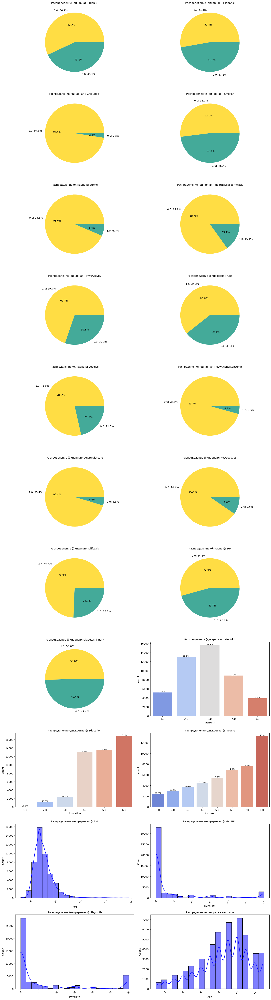

In [17]:


# Разделение колонок на группы
binary_columns = [col for col in df.columns if df[col].nunique() == 2]
discrete_columns = [col for col in df.columns if 2 < df[col].nunique() <= 10]
continuous_columns = [col for col in df.columns if df[col].nunique() > 10]

# Определение числа графиков на одной странице
num_columns = 2  # Количество столбцов в сетке
num_rows = (len(binary_columns) + len(discrete_columns) + len(continuous_columns) + num_columns - 1) // num_columns

# Фигура с сеткой
fig, axs = plt.subplots(num_rows, num_columns, figsize=(15, 5 * num_rows))

# Упорядоченные графики
for i, column in enumerate(binary_columns + discrete_columns + continuous_columns):
    ax = axs[i // num_columns, i % num_columns]
    if column in binary_columns:
        # Для бинарных переменных
        counts = df[column].value_counts(normalize=True) * 100  # Процентное соотношение
        labels = counts.index.map(lambda x: f'{x}: {counts[x]:.1f}%')
        ax.pie(counts, labels=labels, autopct='%1.1f%%', colors=['#FFDD44', '#44AA99'])
        ax.set_title(f'Распределение (бинарная): {column}', fontsize=10)
    elif column in discrete_columns:
        # Для дискретных переменных
        sns.countplot(x=df[column], ax=ax, palette='coolwarm')
        counts = df[column].value_counts(normalize=True) * 100
        for p, count in zip(ax.patches, counts):
            ax.text(p.get_x() + p.get_width() / 2, p.get_height(), f'{count:.1f}%', ha='center', va='bottom', fontsize=8)
        ax.set_title(f'Распределение (дискретная): {column}', fontsize=10)
    elif column in continuous_columns:
        # Для непрерывных переменных
        sns.histplot(df[column], kde=True, bins=20, color='blue', ax=ax)
        counts = df[column].value_counts(normalize=True) * 100
        for tick in ax.get_xticklabels():
            tick.set_rotation(45)
        ax.set_title(f'Распределение (непрерывная): {column}', fontsize=10)

plt.tight_layout()
plt.show()


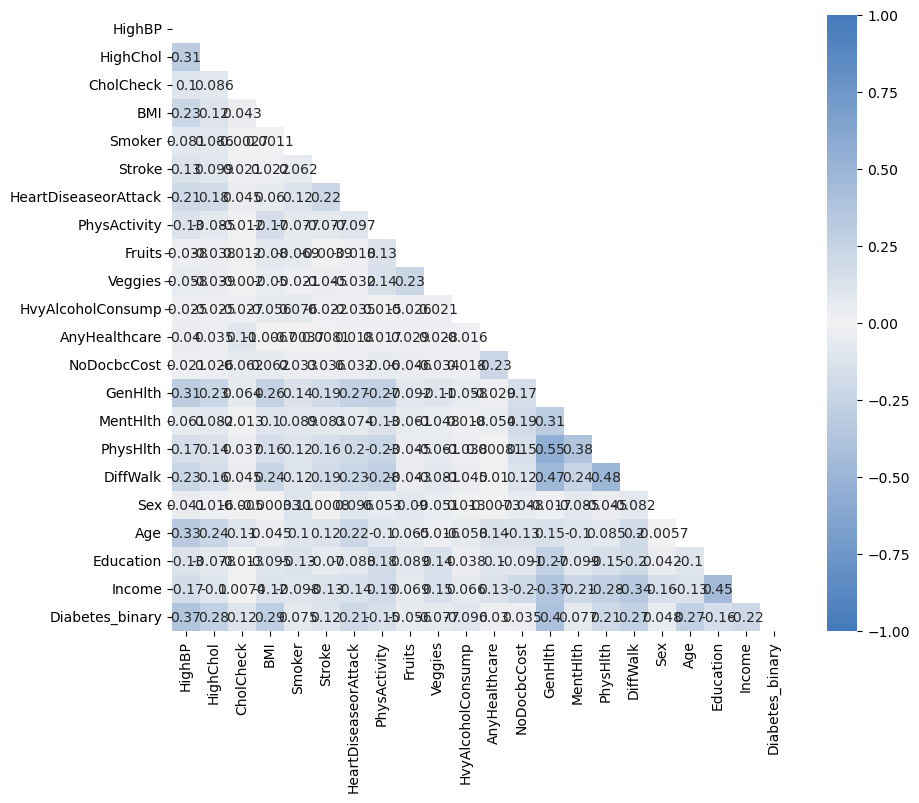

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr,
    mask=mask,
    cmap=sns.diverging_palette(250, 250, as_cmap=True),
    annot = True,
    vmin=-1.0, vmax=1.0,
    square=True, ax=ax);

Объясненная дисперсия по компонентам: [0.17001327 0.08285086 0.06308397 0.05768689 0.05650708 0.05135031
 0.04883585 0.04494943 0.04470019 0.04158783]
Кумулятивная объясненная дисперсия: [0.17001327 0.25286413 0.3159481  0.37363499 0.43014206 0.48149237
 0.53032822 0.57527765 0.61997784 0.66156567]


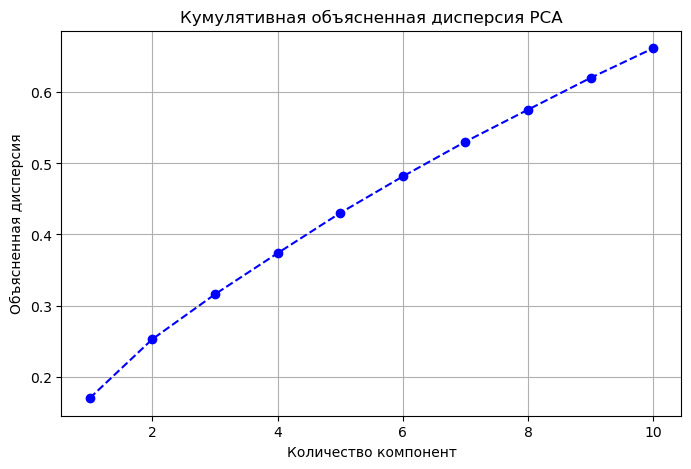

In [21]:


# Разделяем данные
X = df.drop(columns=['Diabetes_binary'])  # Все признаки, кроме целевой переменной
y = df['Diabetes_binary']                # Целевая переменная

# Шаг 1: Нормализация данных (PCA чувствителен к масштабированию)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Масштабируем данные

# Шаг 2: Применение PCA
n_components = 10  # Задаем количество главных компонент (можно подбирать)
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

# Шаг 3: Анализ объясненной дисперсии
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()
print("Объясненная дисперсия по компонентам:", explained_variance)
print("Кумулятивная объясненная дисперсия:", cumulative_variance)

# Визуализация объясненной дисперсии

plt.figure(figsize=(8, 5))
plt.plot(range(1, n_components + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.title('Кумулятивная объясненная дисперсия PCA')
plt.xlabel('Количество компонент')
plt.ylabel('Объясненная дисперсия')
plt.grid()
plt.show()

In [23]:


# Разделение на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,  # 20% данных для тестовой выборки
    random_state=42,  # Фиксируем для воспроизводимости
    stratify=y       # Стратификация по целевой переменной, если данные несбалансированы
)

# Проверим размеры полученных выборок
print(f'Размер тренировочной выборки: {X_train.shape[0]}')
print(f'Размер тестовой выборки: {X_test.shape[0]}')


Размер тренировочной выборки: 37262
Размер тестовой выборки: 9316


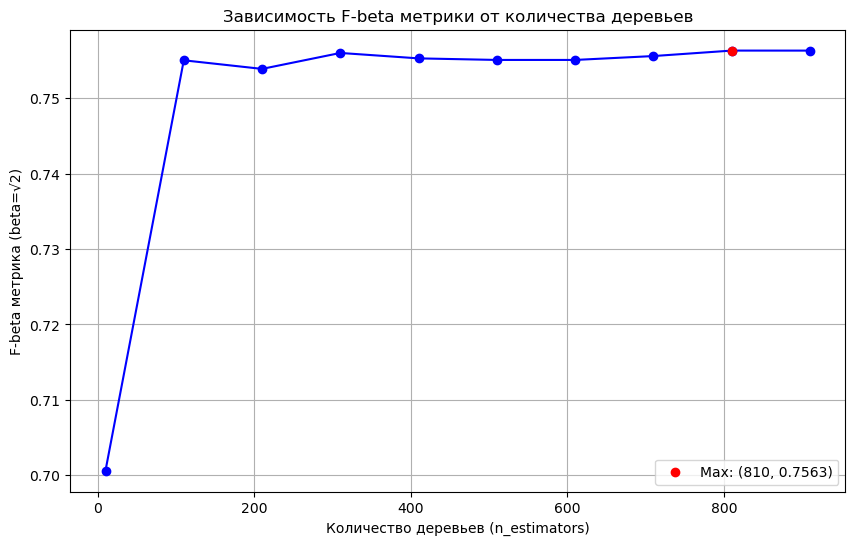

Точка максимума: n_estimators = 810, F-beta = 0.7563


In [25]:


# Параметры
n_estimators_range = range(10, 1001, 100)  # Количество деревьев: от 10 до 1000 с шагом 50
scores = []

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Цикл по количеству деревьев
for n in n_estimators_range:
    model = RandomForestClassifier(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = calculate_fbeta_score(y_test, y_pred)  # Вычисляем F-beta
    scores.append(score)

# Поиск точки максимума
max_score = max(scores)
max_index = scores.index(max_score)
max_n_estimators = n_estimators_range[max_index]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, scores, marker='o', color='blue')
plt.title('Зависимость F-beta метрики от количества деревьев')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('F-beta метрика (beta=√2)')
plt.grid()

# Добавление точки максимума на график
plt.scatter(max_n_estimators, max_score, color='red', label=f'Max: ({max_n_estimators}, {max_score:.4f})', zorder=5)
plt.legend()

plt.show()

# Вывод координат максимума
print(f"Точка максимума: n_estimators = {max_n_estimators}, F-beta = {max_score:.4f}")




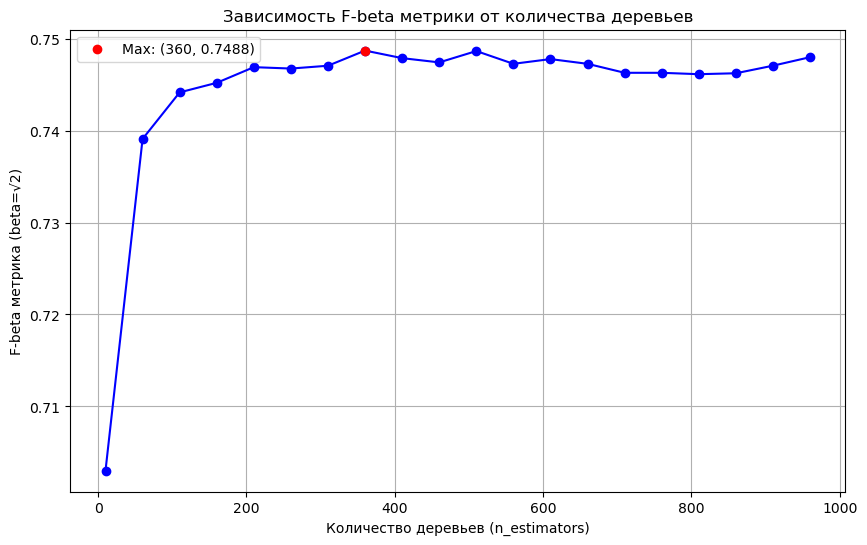

Точка максимума: n_estimators = 360, F-beta = 0.7488


In [27]:


# Параметры
n_estimators_range = range(10, 1001, 50)  # Количество деревьев: от 10 до 1000 с шагом 50
scores = []

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Цикл по количеству деревьев
for n in n_estimators_range:
    model = ExtraTreesClassifier(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = calculate_fbeta_score(y_test, y_pred)  # Вычисляем F-beta
    scores.append(score)

# Поиск точки максимума
max_score = max(scores)
max_index = scores.index(max_score)
max_n_estimators = n_estimators_range[max_index]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, scores, marker='o', color='blue')
plt.title('Зависимость F-beta метрики от количества деревьев')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('F-beta метрика (beta=√2)')
plt.grid()

# Добавление точки максимума на график
plt.scatter(max_n_estimators, max_score, color='red', label=f'Max: ({max_n_estimators}, {max_score:.4f})', zorder=5)
plt.legend()

plt.show()

# Вывод координат максимума
print(f"Точка максимума: n_estimators = {max_n_estimators}, F-beta = {max_score:.4f}")




In [29]:
#бессмысленно
model = RandomForestClassifier(n_estimators= 2000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
score = calculate_fbeta_score(y_test, y_pred)  # Вычисляем F-beta
score

0.7571271174769316

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  44 out of  50 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  44 out of  50 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=12)]: Done  50 out of  50 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.


building tree 1 of 50
building tree 2 of 50
building tree 3 of 50
building tree 4 of 50
building tree 5 of 50
building tree 6 of 50
building tree 7 of 50
building tree 8 of 50
building tree 9 of 50
building tree 10 of 50
building tree 11 of 50
building tree 12 of 50
building tree 13 of 50
building tree 14 of 50
building tree 15 of 50
building tree 16 of 50
building tree 17 of 50
building tree 18 of 50
building tree 19 of 50
building tree 20 of 50
building tree 21 of 50
building tree 22 of 50
building tree 23 of 50
building tree 24 of 50
building tree 25 of 50
building tree 26 of 50
building tree 27 of 50
building tree 28 of 50
building tree 29 of 50
building tree 30 of 50
building tree 31 of 50
building tree 32 of 50
building tree 33 of 50
building tree 34 of 50
building tree 35 of 50
building tree 36 of 50
building tree 37 of 50
building tree 38 of 50
building tree 39 of 50
building tree 40 of 50
building tree 41 of 50
building tree 42 of 50
building tree 43 of 50
building tree 44 of 

[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 104 tasks      | elapsed:    0.1s


building tree 128 of 150
building tree 129 of 150
building tree 130 of 150
building tree 131 of 150
building tree 132 of 150
building tree 133 of 150
building tree 134 of 150
building tree 135 of 150
building tree 136 of 150
building tree 137 of 150
building tree 138 of 150
building tree 139 of 150
building tree 140 of 150
building tree 141 of 150
building tree 142 of 150
building tree 143 of 150
building tree 144 of 150
building tree 145 of 150
building tree 146 of 150
building tree 147 of 150
building tree 148 of 150
building tree 149 of 150
building tree 150 of 150
building tree 1 of 250
building tree 2 of 250
building tree 3 of 250
building tree 4 of 250
building tree 5 of 250
building tree 6 of 250
building tree 7 of 250
building tree 8 of 250
building tree 9 of 250
building tree 10 of 250
building tree 11 of 250
building tree 12 of 250
building tree 13 of 250
building tree 14 of 250
building tree 15 of 250
building tree 16 of 250
building tree 17 of 250
building tree 18 of 250
bu

[Parallel(n_jobs=-1)]: Done 150 out of 150 | elapsed:    0.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 104 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 150 out of 150 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.0s


building tree 26 of 250
building tree 27 of 250
building tree 28 of 250
building tree 29 of 250
building tree 30 of 250
building tree 31 of 250
building tree 32 of 250
building tree 33 of 250
building tree 34 of 250
building tree 35 of 250
building tree 36 of 250
building tree 37 of 250
building tree 38 of 250
building tree 39 of 250
building tree 40 of 250
building tree 41 of 250
building tree 42 of 250
building tree 43 of 250
building tree 44 of 250
building tree 45 of 250
building tree 46 of 250
building tree 47 of 250
building tree 48 of 250
building tree 49 of 250
building tree 50 of 250
building tree 51 of 250
building tree 52 of 250
building tree 53 of 250
building tree 54 of 250
building tree 55 of 250
building tree 56 of 250
building tree 57 of 250
building tree 58 of 250
building tree 59 of 250
building tree 60 of 250
building tree 61 of 250
building tree 62 of 250
building tree 63 of 250
building tree 64 of 250
building tree 65 of 250
building tree 66 of 250
building tree 67

... (3,131 outputs left out)

building tree 853 of 1450
building tree 854 of 1450
building tree 855 of 1450
building tree 856 of 1450
building tree 857 of 1450
building tree 858 of 1450
building tree 859 of 1450
building tree 860 of 1450
building tree 861 of 1450
building tree 862 of 1450
building tree 863 of 1450
building tree 864 of 1450
building tree 865 of 1450
building tree 866 of 1450
building tree 867 of 1450
building tree 868 of 1450
building tree 869 of 1450
building tree 870 of 1450
building tree 871 of 1450
building tree 872 of 1450
building tree 873 of 1450
building tree 874 of 1450
building tree 875 of 1450
building tree 876 of 1450
building tree 877 of 1450
building tree 878 of 1450
building tree 879 of 1450
building tree 880 of 1450
building tree 881 of 1450
building tree 882 of 1450
building tree 883 of 1450
building tree 884 of 1450
building tree 885 of 1450
building tree 886 of 1450
building tree 887 of 1450
building tree 888 of 1450
building tree 889 of 1450
building tree 890 of 1450
building tre

[Parallel(n_jobs=-1)]: Done 1128 tasks      | elapsed:    3.0s


building tree 1167 of 1450
building tree 1168 of 1450
building tree 1169 of 1450
building tree 1170 of 1450
building tree 1171 of 1450
building tree 1172 of 1450
building tree 1173 of 1450
building tree 1174 of 1450
building tree 1175 of 1450
building tree 1176 of 1450
building tree 1177 of 1450
building tree 1178 of 1450
building tree 1179 of 1450
building tree 1180 of 1450
building tree 1181 of 1450
building tree 1182 of 1450
building tree 1183 of 1450
building tree 1184 of 1450
building tree 1185 of 1450
building tree 1186 of 1450
building tree 1187 of 1450
building tree 1188 of 1450
building tree 1189 of 1450
building tree 1190 of 1450
building tree 1191 of 1450
building tree 1192 of 1450
building tree 1193 of 1450
building tree 1194 of 1450
building tree 1195 of 1450
building tree 1196 of 1450
building tree 1197 of 1450
building tree 1198 of 1450
building tree 1199 of 1450
building tree 1200 of 1450
building tree 1201 of 1450
building tree 1202 of 1450
building tree 1203 of 1450
b

[Parallel(n_jobs=-1)]: Done 1450 out of 1450 | elapsed:    4.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 104 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 264 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 488 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 1128 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 1450 out of 1450 | elapsed:    0.2s finished


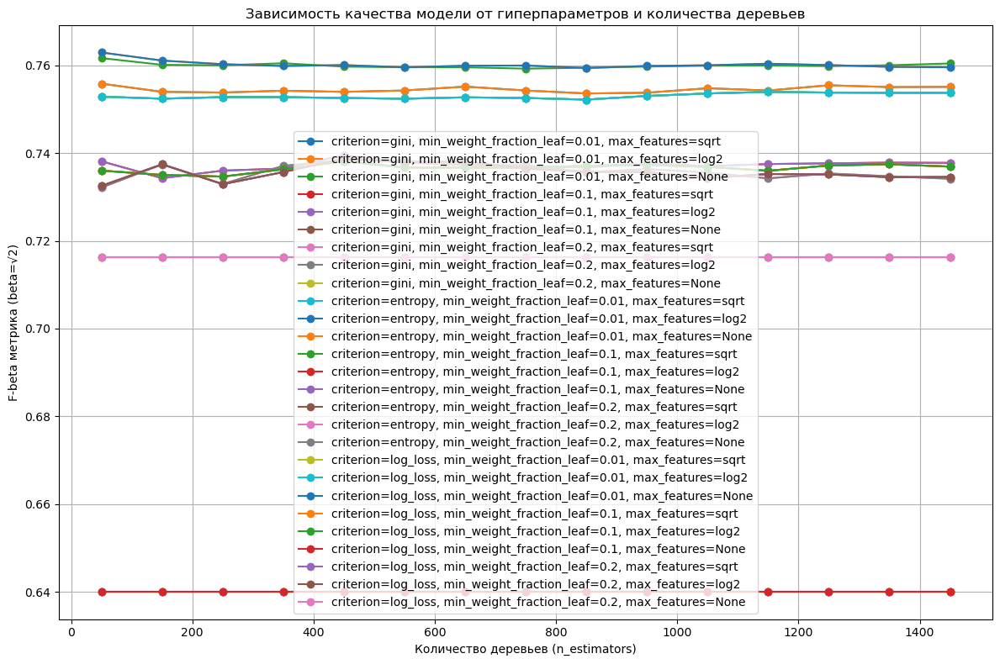

In [177]:

# Параметры
n_estimators_range = range(50, 1501, 100)  # Количество деревьев: от 50 до 1500 с шагом 100
criteria = ["gini", "entropy", "log_loss"]
min_weight_fraction_leaf = [0.01, 0.1, 0.2]
max_features = ["sqrt", "log2", None]
scores = {crit: {min_wf: {max_f: [] for max_f in max_features} for min_wf in min_weight_fraction_leaf} for crit in criteria}

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Цикл по гиперпараметрам
for crit in criteria:
    for min_wf in min_weight_fraction_leaf:
        for max_f in max_features:
            for n in n_estimators_range:
                model = RandomForestClassifier(n_estimators=n, criterion=crit, min_weight_fraction_leaf=min_wf, max_features=max_f, n_jobs=-1, verbose=3, class_weight='balanced', random_state=42)
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)
                score = calculate_fbeta_score(y_test, y_pred)
                scores[crit][min_wf][max_f].append(score)

# Построение общего графика
plt.figure(figsize=(12, 8))
for crit in criteria:
    for min_wf in min_weight_fraction_leaf:
        for max_f in max_features:
            plt.plot(n_estimators_range, scores[crit][min_wf][max_f], marker='o', label=f'criterion={crit}, min_weight_fraction_leaf={min_wf}, max_features={max_f}')

plt.title('Зависимость качества модели от гиперпараметров и количества деревьев')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('F-beta метрика (beta=√2)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [179]:
#gini sqrt
#entropy log2
#logloss none

In [39]:
model = RandomForestClassifier(n_estimators= 10000, random_state=4, criterion = "log_loss", min_weight_fraction_leaf = 0.00, max_features = None, n_jobs=-1, verbose=1, class_weight='balanced', max_depth = 7, min_samples_split=2, min_samples_leaf=1, max_leaf_nodes=None, min_impurity_decrease = 0.0, bootstrap = True, warm_start=False)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
score = calculate_fbeta_score(y_test, y_pred)  # Вычисляем F-beta
score

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.9s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 776 tasks      | elapsed:    4.0s
[Parallel(n_jobs=-1)]: Done 1226 tasks      | elapsed:    6.4s
[Parallel(n_jobs=-1)]: Done 1776 tasks      | elapsed:    9.5s
[Parallel(n_jobs=-1)]: Done 2426 tasks      | elapsed:   13.1s
[Parallel(n_jobs=-1)]: Done 3176 tasks      | elapsed:   17.4s
[Parallel(n_jobs=-1)]: Done 4026 tasks      | elapsed:   22.3s
[Parallel(n_jobs=-1)]: Done 4976 tasks      | elapsed:   28.1s
[Parallel(n_jobs=-1)]: Done 6026 tasks      | elapsed:   34.5s
[Parallel(n_jobs=-1)]: Done 7176 tasks      | elapsed:   41.6s
[Parallel(n_jobs=-1)]: Done 8426 tasks      | elapsed:   49.4s
[Parallel(n_jobs=-1)]: Done 9776 tasks      | elapsed:   58.0s
[Parallel(n_jobs=-1)]: Done 10000 out of

0.7618521841142779

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 426 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 1226 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 1776 tasks      | elapsed:    0.3s
[Parallel(n_jobs=12)]: Done 2426 tasks      | elapsed:    0.5s
[Parallel(n_jobs=12)]: Done 3176 tasks      | elapsed:    0.7s
[Parallel(n_jobs=12)]: Done 4026 tasks      | elapsed:    0.9s
[Parallel(n_jobs=12)]: Done 4976 tasks      | elapsed:    1.1s
[Parallel(n_jobs=12)]: Done 6026 tasks      | elapsed:    1.4s
[Parallel(n_jobs=12)]: Done 7176 tasks      | elapsed:    1.6s
[Parallel(n_jobs=12)]: Done 8426 tasks      | elapsed:    1.9s
[Parallel(n_jobs=12)]: Done 9776 tasks      | elapsed:    2.2s
[Parallel(n_jobs=12)]: Done 10000 out of

Best Threshold for Random Forest: 0.23
Best F-beta Score for Random Forest: 0.81


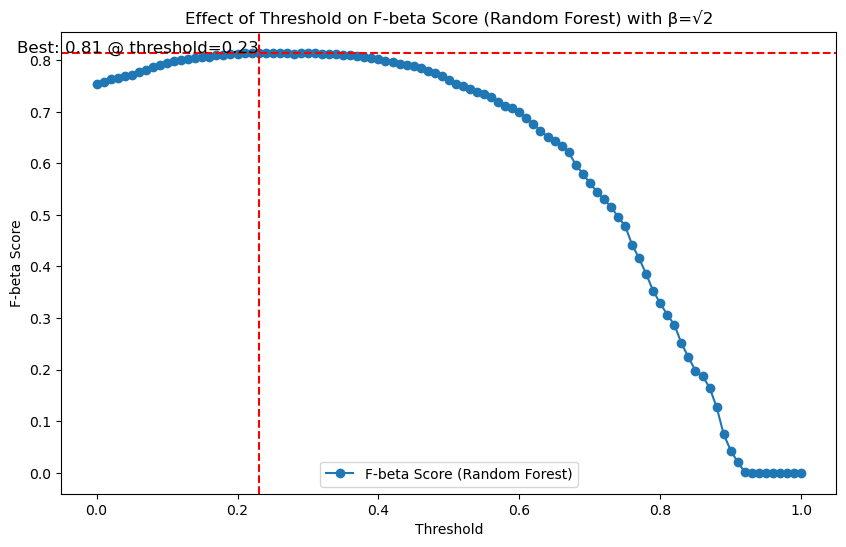

In [41]:
# Получение вероятностей для класса 1 (положительного класса)
y_pred_proba_rf = model.predict_proba(X_test)[:, 1]

# Оценка моделей с разными порогами
thresholds = np.linspace(0, 1, 101)
fbeta_scores_rf = []

for threshold in thresholds:
    # Применение порога для получения предсказаний
    y_pred_optimal_rf = (y_pred_proba_rf >= threshold).astype(int)
    
    # Вычисление F-beta метрики с β=√2
    fbeta_rf = fbeta_score(y_test, y_pred_optimal_rf, beta=np.sqrt(2))
    fbeta_scores_rf.append(fbeta_rf)

# Нахождение лучшего порога по F-beta метрике
best_threshold_rf = thresholds[np.argmax(fbeta_scores_rf)]
best_fbeta_rf = np.max(fbeta_scores_rf)

# Выводим лучший порог и соответствующее значение F-beta
print(f"Best Threshold for Random Forest: {best_threshold_rf:.2f}")
print(f"Best F-beta Score for Random Forest: {best_fbeta_rf:.2f}")

# Построение графика F-beta по порогам
plt.figure(figsize=(10, 6))
plt.plot(thresholds, fbeta_scores_rf, marker='o', label="F-beta Score (Random Forest)")
plt.xlabel('Threshold')
plt.ylabel('F-beta Score')
plt.title('Effect of Threshold on F-beta Score (Random Forest) with β=√2')
plt.axvline(x=best_threshold_rf, color='r', linestyle='--')
plt.axhline(y=best_fbeta_rf, color='r', linestyle='--')
plt.text(best_threshold_rf, best_fbeta_rf, f'Best: {best_fbeta_rf:.2f} @ threshold={best_threshold_rf:.2f}', fontsize=12, ha='right')
plt.legend()
plt.show()

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.9s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 776 tasks      | elapsed:    4.1s
[Parallel(n_jobs=-1)]: Done 1226 tasks      | elapsed:    6.5s
[Parallel(n_jobs=-1)]: Done 1776 tasks      | elapsed:    9.4s
[Parallel(n_jobs=-1)]: Done 2000 out of 2000 | elapsed:   10.6s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 426 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 1226 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 1776 tasks      | elapsed:    0.2s
[Parallel(n_job

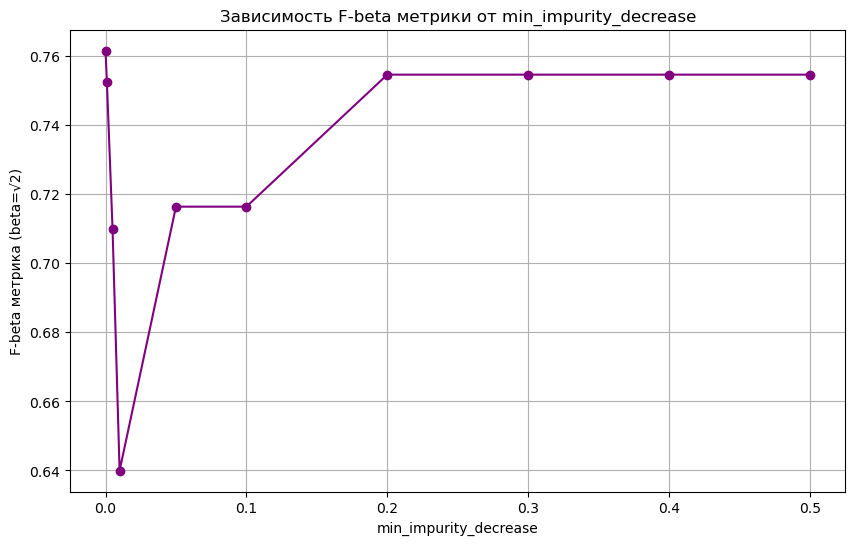

In [335]:


# Параметры
min_impurity_decrease_range = [0.0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
n_estimators = 100
scores = []

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Цикл по min_impurity_decrease
for min_impurity in min_impurity_decrease_range:
    model = RandomForestClassifier(n_estimators= 2000, random_state=4, criterion = "log_loss", min_weight_fraction_leaf = 0.00, max_features = None, n_jobs=-1, verbose=1, class_weight='balanced', max_depth = 7, min_samples_split=2, min_samples_leaf=1, max_leaf_nodes=None, min_impurity_decrease = min_impurity)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = calculate_fbeta_score(y_test, y_pred)
    scores.append(score)

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(
    min_impurity_decrease_range,
    scores,
    marker='o',
    color='purple'
)
plt.title('Зависимость F-beta метрики от min_impurity_decrease')
plt.xlabel('min_impurity_decrease')
plt.ylabel('F-beta метрика (beta=√2)')
plt.grid(True)
plt.show()
# вывод - лучше не трогать

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.9s
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 776 tasks      | elapsed:    4.1s
[Parallel(n_jobs=-1)]: Done 1226 tasks      | elapsed:    6.5s
[Parallel(n_jobs=-1)]: Done 1776 tasks      | elapsed:    9.5s
[Parallel(n_jobs=-1)]: Done 2000 out of 2000 | elapsed:   10.8s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 426 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 776 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 1226 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 1776 tasks      | elapsed:    0.3s
[Parallel(n_job

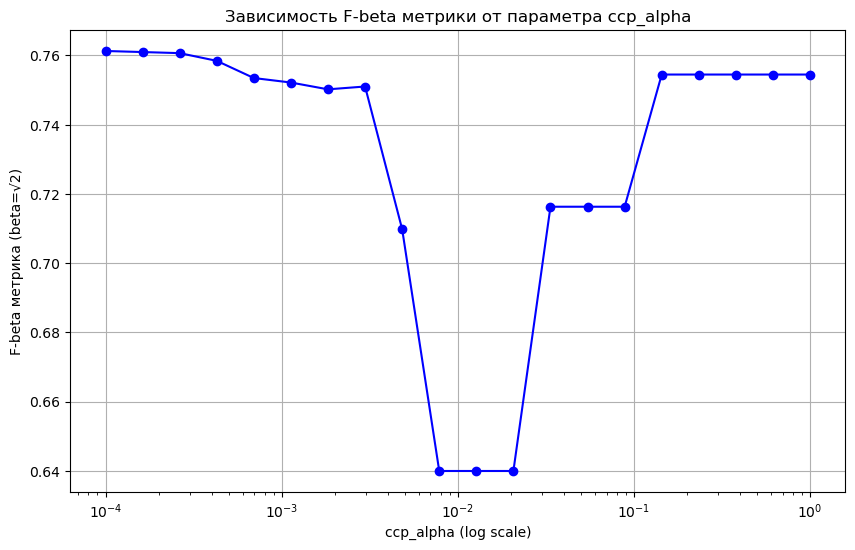

Лучший ccp_alpha: 0.0001, Максимальная F-beta метрика: 0.7613


In [357]:
ccp_alphas = np.logspace(-4, 0, 20)  # Логарифмическая шкала от 0.0001 до 1.0
scores = []

for ccp in ccp_alphas:
    model = RandomForestClassifier(n_estimators= 2000, random_state=4, criterion = "log_loss", min_weight_fraction_leaf = 0.00, max_features = None, n_jobs=-1, verbose=1, class_weight='balanced', max_depth = 7, min_samples_split=2, min_samples_leaf=1, max_leaf_nodes=None, min_impurity_decrease = 0.0, bootstrap = True, warm_start=False, ccp_alpha=ccp)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = calculate_fbeta_score(y_test, y_pred)
    scores.append(score)

plt.figure(figsize=(10, 6))
plt.semilogx(ccp_alphas, scores, marker='o', color='blue')  # Используем логарифмическую ось
plt.title('Зависимость F-beta метрики от параметра ccp_alpha')
plt.xlabel('ccp_alpha (log scale)')
plt.ylabel('F-beta метрика (beta=√2)')
plt.grid()
plt.show()

# Вывод точки максимума
max_score = max(scores)
best_ccp_alpha = ccp_alphas[scores.index(max_score)]
print(f"Лучший ccp_alpha: {best_ccp_alpha}, Максимальная F-beta метрика: {max_score:.4f}")

#ЛУЧШЕ НЕ ТРОГАТЬ

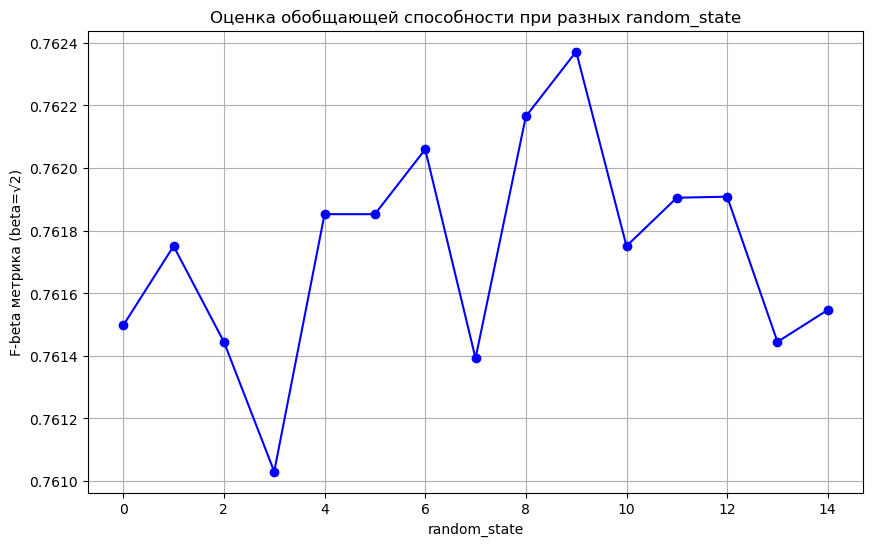

Средняя F-beta метрика: 0.7617
Стандартное отклонение F-beta метрики: 0.0003


In [366]:


# Заданные параметры модели
model_params = {
    'n_estimators': 10000,
    'criterion': 'log_loss',
    'min_weight_fraction_leaf': 0.0,
    'max_features': None,
    'n_jobs': -1,
    'class_weight': 'balanced',
    'max_depth': 7,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'max_leaf_nodes': None,
    'min_impurity_decrease': 0.0,
    'bootstrap': True,
    'warm_start': False
}

# Перебор random_state
random_states = range(15)
scores = []

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Цикл по random_state
for random_state in random_states:
    model = RandomForestClassifier(random_state=random_state, **model_params)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = calculate_fbeta_score(y_test, y_pred)
    scores.append(score)

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(random_states, scores, marker='o', color='blue')
plt.title('Оценка обобщающей способности при разных random_state')
plt.xlabel('random_state')
plt.ylabel('F-beta метрика (beta=√2)')
plt.grid(True)
plt.show()

# Вывод среднего и стандартного отклонения метрики
mean_score = np.mean(scores)
std_score = np.std(scores)
print(f'Средняя F-beta метрика: {mean_score:.4f}')
print(f'Стандартное отклонение F-beta метрики: {std_score:.4f}')


In [43]:
#бустинг



# Градиентный бустинг с учетом дисбаланса
model = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)

# Обучение
model.fit(X_train, y_train)

# Предсказания
y_pred = model.predict(X_test)

# Метрика
score = fbeta_score(y_test, y_pred, beta=np.sqrt(2))
print(f'F-beta метрика: {score:.4f}')

#рандомные параметры



F-beta метрика: 0.7669


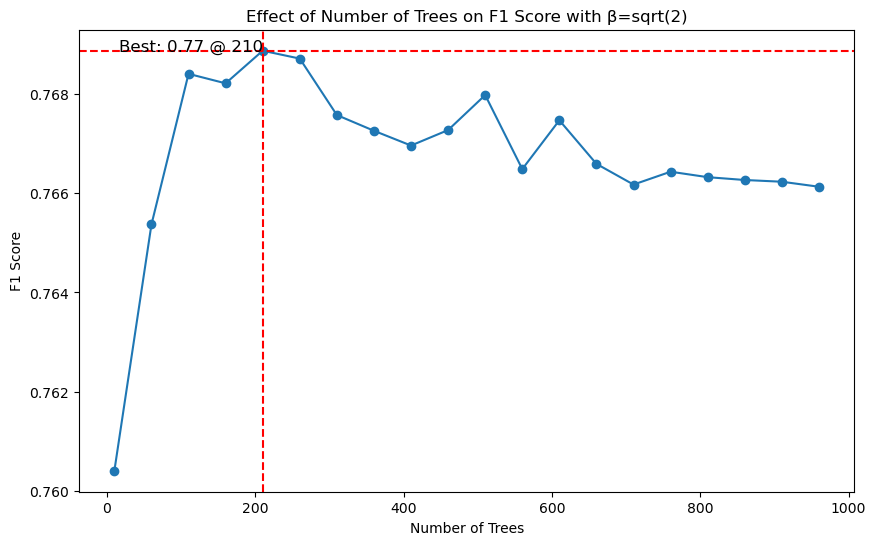

In [45]:


# Диапазон значений количества деревьев
n_estimators_range = range(10, 1001, 50)  # Например, от 10 до 200 с шагом 10

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Массивы для хранения значений метрики F1
f1_scores = []

# Перебор различных значений количества деревьев
for n_estimators in n_estimators_range:
    # Создание градиентного бустинга с текущим количеством деревьев
    clf = GradientBoostingClassifier(n_estimators=n_estimators, random_state=42)
    
    # Обучение модели
    clf.fit(X_train, y_train)
    
    # Прогнозирование на тестовой выборке
    y_pred = clf.predict(X_test)
    
    # Вычисление метрики F1 с бета = sqrt(2)
    f1 = calculate_fbeta_score(y_test, y_pred)
    
    # Сохранение значений метрики F1
    f1_scores.append(f1)

# Нахождение индекса максимума метрики F1
best_index = np.argmax(f1_scores)
best_n_estimators = n_estimators_range[best_index]
best_f1 = f1_scores[best_index]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, f1_scores, marker='o')
plt.xlabel('Number of Trees')
plt.ylabel('F1 Score')
plt.title('Effect of Number of Trees on F1 Score with β=sqrt(2)')
plt.axvline(x=best_n_estimators, color='r', linestyle='--')
plt.axhline(y=best_f1, color='r', linestyle='--')
plt.text(best_n_estimators, best_f1, f'Best: {best_f1:.2f} @ {best_n_estimators}', fontsize=12, ha='right')
plt.show()


210 деревьев

In [24]:
#основной оптимальный бустинг

def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

model = GradientBoostingClassifier(n_estimators=210, random_state=42, verbose=0, max_depth=4)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
score = calculate_fbeta_score(y_test, y_pred)  # Вычисляем F-beta
score

0.770117308088084

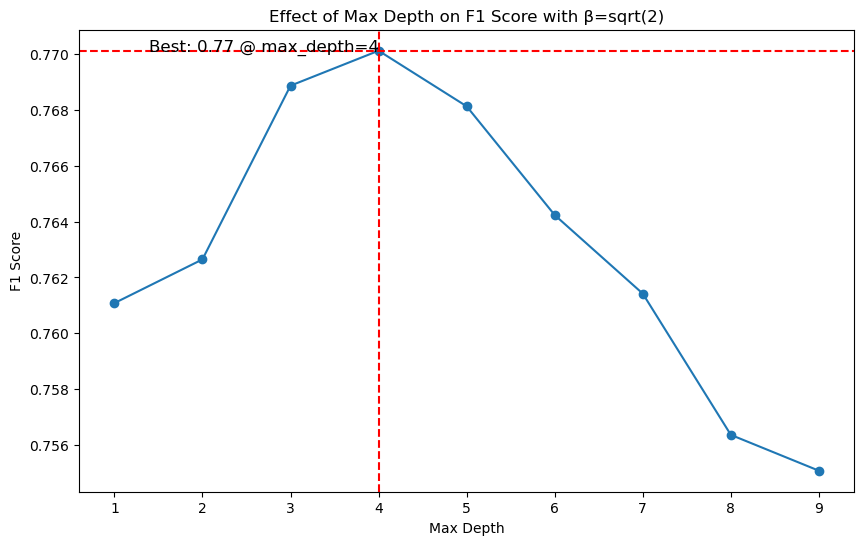

In [22]:


# Диапазон значений максимальной глубины дерева
max_depth_range = range(1, 10)  # Например, от 1 до 20

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Массивы для хранения значений метрики F1
f1_scores = []

# Фиксированное количество деревьев
n_estimators = 210

# Перебор различных значений максимальной глубины дерева
for max_depth in max_depth_range:
    # Создание градиентного бустинга с текущим значением max_depth и фиксированным количеством деревьев
    clf = GradientBoostingClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
    
    # Обучение модели
    clf.fit(X_train, y_train)
    
    # Прогнозирование на тестовой выборке
    y_pred = clf.predict(X_test)
    
    # Вычисление метрики F1 с бета = sqrt(2)
    f1 = calculate_fbeta_score(y_test, y_pred)
    
    # Сохранение значений метрики F1
    f1_scores.append(f1)

# Нахождение индекса максимума метрики F1
best_index = np.argmax(f1_scores)
best_max_depth = max_depth_range[best_index]
best_f1 = f1_scores[best_index]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(max_depth_range, f1_scores, marker='o')
plt.xlabel('Max Depth')
plt.ylabel('F1 Score')
plt.title('Effect of Max Depth on F1 Score with β=sqrt(2)')
plt.axvline(x=best_max_depth, color='r', linestyle='--')
plt.axhline(y=best_f1, color='r', linestyle='--')
plt.text(best_max_depth, best_f1, f'Best: {best_f1:.2f} @ max_depth={best_max_depth}', fontsize=12, ha='right')
plt.show()


глубина 4

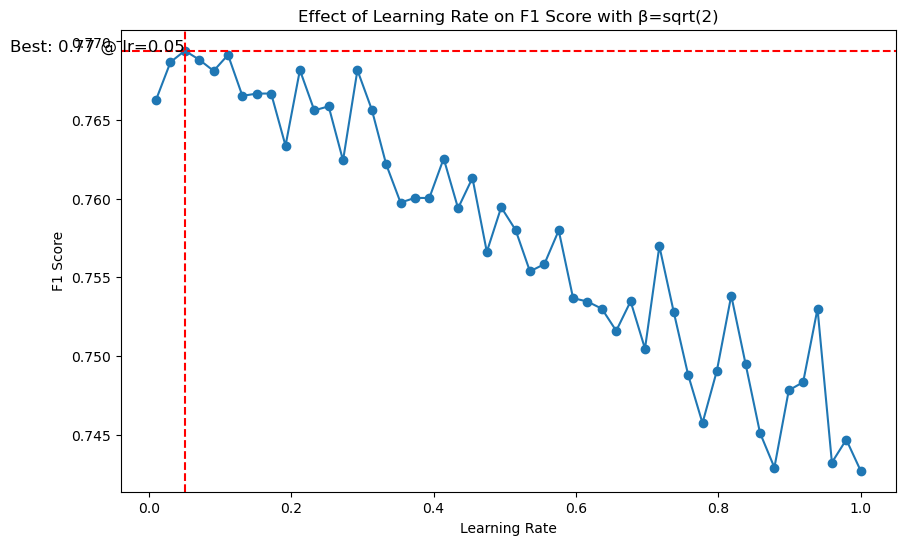

In [27]:

# Диапазон значений learning_rate
learning_rate_range = np.linspace(0.01, 1.0, 50)  # 50 значений от 0.01 до 1.0

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Массивы для хранения значений метрики F1
f1_scores = []

# Фиксированное количество деревьев
n_estimators = 210
max_depth = 4

# Перебор различных значений learning_rate
for learning_rate in learning_rate_range:
    # Создание градиентного бустинга с текущим значением learning_rate
    clf = GradientBoostingClassifier(n_estimators=n_estimators, max_depth=max_depth, verbose=0, learning_rate=learning_rate, random_state=42)
    
    # Обучение модели
    clf.fit(X_train, y_train)
    
    # Прогнозирование на тестовой выборке
    y_pred = clf.predict(X_test)
    
    # Вычисление метрики F1 с бета = sqrt(2)
    f1 = calculate_fbeta_score(y_test, y_pred)
    
    # Сохранение значений метрики F1
    f1_scores.append(f1)

# Нахождение индекса максимума метрики F1
best_index = np.argmax(f1_scores)
best_learning_rate = learning_rate_range[best_index]
best_f1 = f1_scores[best_index]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(learning_rate_range, f1_scores, marker='o')
plt.xlabel('Learning Rate')
plt.ylabel('F1 Score')
plt.title('Effect of Learning Rate on F1 Score with β=sqrt(2)')
plt.axvline(x=best_learning_rate, color='r', linestyle='--')
plt.axhline(y=best_f1, color='r', linestyle='--')
plt.text(best_learning_rate, best_f1, f'Best: {best_f1:.2f} @ lr={best_learning_rate:.2f}', fontsize=12, ha='right')
plt.show()


learning rate 0.05

      Iter       Train Loss      OOB Improve   Remaining Time 
         1           1.3595           0.0258            2.71s
         2           1.3352           0.0238            2.59s
         3           1.3122           0.0222            2.52s
         4           1.2882           0.0201            2.48s
         5           1.2711           0.0185            2.40s
         6           1.2577           0.0173            2.34s
         7           1.2404           0.0150            2.30s
         8           1.2235           0.0142            2.25s
         9           1.2081           0.0131            2.21s
        10           1.1999           0.0130            2.20s
        20           1.1198           0.0056            2.00s
        30           1.0727           0.0046            1.86s
        40           1.0485           0.0024            1.72s
        50           1.0292           0.0023            1.60s
        60           1.0172           0.0001            1.49s
       

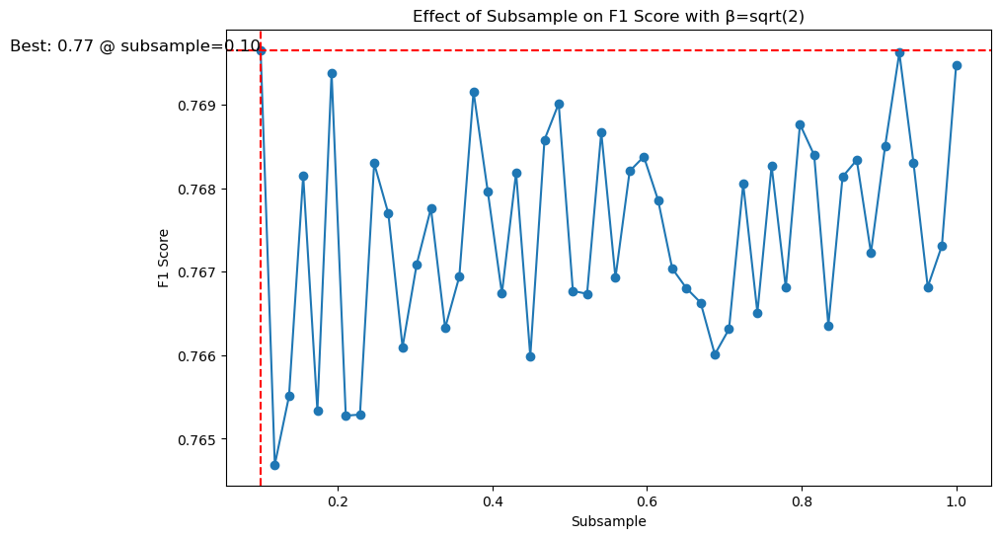

In [29]:
# Диапазон значений subsample
subsample_range = np.linspace(0.1, 1.0, 50)  # 50 значений от 0.1 до 1.0

# Массивы для хранения значений метрики F1
f1_scores = []

# Фиксированные значения других параметров
n_estimators = 210
max_depth = 4
learning_rate = 0.05  # Оптимальное значение из предыдущих экспериментов

# Перебор различных значений subsample
for subsample in subsample_range:
    # Создание градиентного бустинга с текущим значением subsample
    clf = GradientBoostingClassifier(
        n_estimators=n_estimators, 
        max_depth=max_depth, 
        verbose=1, 
        learning_rate=learning_rate, 
        subsample=subsample, 
        random_state=42
    )
    
    # Обучение модели
    clf.fit(X_train, y_train)
    
    # Прогнозирование на тестовой выборке
    y_pred = clf.predict(X_test)
    
    # Вычисление метрики F1 с β = sqrt(2)
    f1 = calculate_fbeta_score(y_test, y_pred)
    
    # Сохранение значений метрики F1
    f1_scores.append(f1)

# Нахождение индекса максимума метрики F1
best_index = np.argmax(f1_scores)
best_subsample = subsample_range[best_index]
best_f1 = f1_scores[best_index]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(subsample_range, f1_scores, marker='o')
plt.xlabel('Subsample')
plt.ylabel('F1 Score')
plt.title('Effect of Subsample on F1 Score with β=sqrt(2)')
plt.axvline(x=best_subsample, color='r', linestyle='--')
plt.axhline(y=best_f1, color='r', linestyle='--')
plt.text(best_subsample, best_f1, f'Best: {best_f1:.2f} @ subsample={best_subsample:.2f}', fontsize=12, ha='right')
plt.show()


subsample 0.1

In [30]:
# Возможные значения для параметра loss
loss_values = ['log_loss', 'exponential']

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Массив для хранения значений метрики F1
f1_scores = []

# Фиксированные значения других гиперпараметров
learning_rate = 0.1
n_estimators = 210
max_depth = 4

# Перебор значений loss
for loss in loss_values:
    # Создание градиентного бустинга с текущим значением loss
    clf = GradientBoostingClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        loss=loss,
        random_state=42
    )
    
    # Обучение модели
    clf.fit(X_train, y_train)
    
    # Прогнозирование на тестовой выборке
    y_pred = clf.predict(X_test)
    
    # Вычисление метрики F1 с β=sqrt(2)
    f1 = calculate_fbeta_score(y_test, y_pred)
    
    # Сохранение значения метрики F1
    f1_scores.append(f1)

# Нахождение наилучшей функции потерь
best_index = np.argmax(f1_scores)
best_loss = loss_values[best_index]
best_f1 = f1_scores[best_index]

# Печать результатов
print("Результаты для различных значений loss:")
for loss, f1 in zip(loss_values, f1_scores):
    print(f"Loss: {loss}, F1 (β=sqrt(2)): {f1:.4f}")

print(f"\nЛучшая функция потерь: {best_loss}, F1 (β=sqrt(2)): {best_f1:.4f}")


Результаты для различных значений loss:
Loss: log_loss, F1 (β=sqrt(2)): 0.7701
Loss: exponential, F1 (β=sqrt(2)): 0.7711

Лучшая функция потерь: exponential, F1 (β=sqrt(2)): 0.7711


loss  exponential 

In [47]:
# Возможные значения для параметра max_features
max_features_values = [None, 'sqrt', 'log2', 0.5, 0.7]  # None = использовать все признаки, остальное - частичный выбор

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Массив для хранения значений метрики F1
f1_scores = []

# Фиксированные значения других гиперпараметров
learning_rate = 0.1
n_estimators = 210
max_depth = 4

# Перебор значений max_features
for max_features in max_features_values:
    # Создание градиентного бустинга с текущим значением max_features
    clf = GradientBoostingClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        max_features=max_features,
        random_state=42
    )
    
    # Обучение модели
    clf.fit(X_train, y_train)
    
    # Прогнозирование на тестовой выборке
    y_pred = clf.predict(X_test)
    
    # Вычисление метрики F1 с β=sqrt(2)
    f1 = calculate_fbeta_score(y_test, y_pred)
    
    # Сохранение значения метрики F1
    f1_scores.append(f1)

# Нахождение наилучшего значения max_features
best_index = np.argmax(f1_scores)
best_max_features = max_features_values[best_index]
best_f1 = f1_scores[best_index]

# Печать результатов
print("Результаты для различных значений max_features:")
for max_features, f1 in zip(max_features_values, f1_scores):
    print(f"Max Features: {max_features}, F1 (β=sqrt(2)): {f1:.4f}")

print(f"\nЛучшее значение max_features: {best_max_features}, F1 (β=sqrt(2)): {best_f1:.4f}")


Результаты для различных значений max_features:
Max Features: None, F1 (β=sqrt(2)): 0.7701
Max Features: sqrt, F1 (β=sqrt(2)): 0.7697
Max Features: log2, F1 (β=sqrt(2)): 0.7697
Max Features: 0.5, F1 (β=sqrt(2)): 0.7669
Max Features: 0.7, F1 (β=sqrt(2)): 0.7670

Лучшее значение max_features: None, F1 (β=sqrt(2)): 0.7701


max_features: None

In [55]:
#основной оптимальный бустинг

def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

model = GradientBoostingClassifier(n_estimators=210, random_state=42, verbose=0, max_depth=4, learning_rate=0.1, loss='log_loss')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
score = calculate_fbeta_score(y_test, y_pred)  # Вычисляем F-beta
score

0.770117308088084

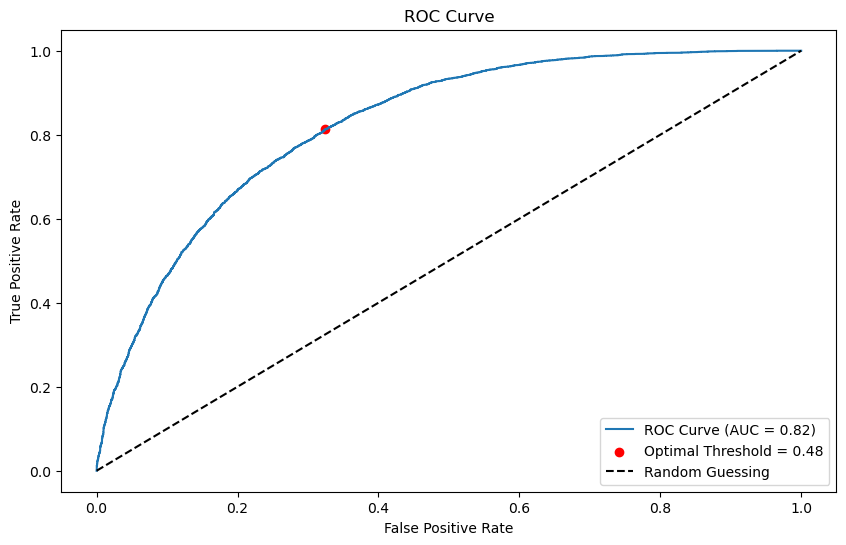

Classification Report with Optimal Threshold:
              precision    recall  f1-score   support

         0.0       0.78      0.68      0.72      4602
         1.0       0.72      0.81      0.76      4714

    accuracy                           0.74      9316
   macro avg       0.75      0.74      0.74      9316
weighted avg       0.75      0.74      0.74      9316



In [57]:



# Получение вероятностей для положительного класса (1)
y_pred_prob = clf.predict_proba(X_test)[:, 1]

# Построение ROC-кривой
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

# Вычисление AUC
auc_score = roc_auc_score(y_test, y_pred_prob)

# Найти оптимальный порог
# Оптимизация метрики: Максимизация разницы между True Positive Rate и False Positive Rate
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.scatter(fpr[optimal_idx], tpr[optimal_idx], color='red', label=f'Optimal Threshold = {optimal_threshold:.2f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

# Применение оптимального порога для получения предсказаний
y_pred_optimal = (y_pred_prob >= optimal_threshold).astype(int)

# Оценка модели с новым порогом
print("Classification Report with Optimal Threshold:")
print(classification_report(y_test, y_pred_optimal))


Best Threshold: 0.27
Best F-beta Score: 0.82


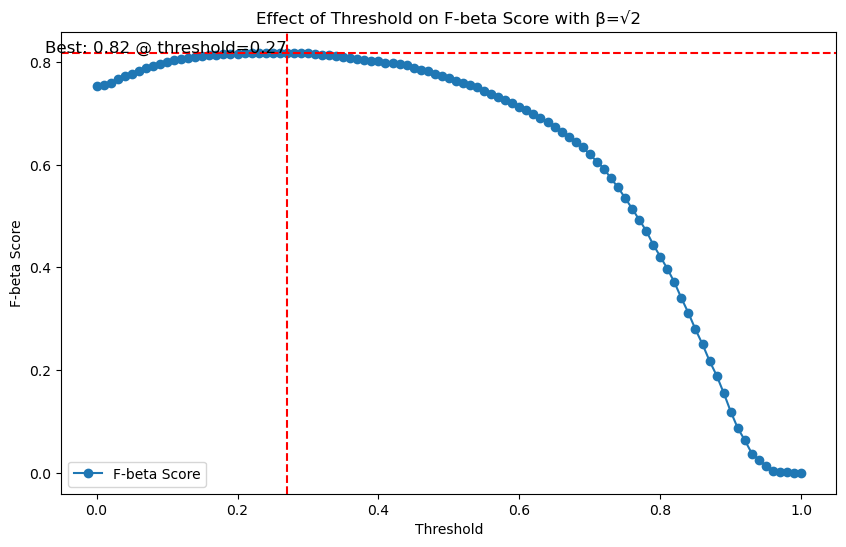

In [59]:
# Получение вероятностей для класса 1 (положительного класса)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Оценка моделей с разными порогами
thresholds = np.linspace(0, 1, 101)
fbeta_scores = []

for threshold in thresholds:
    # Применение порога для получения предсказаний
    y_pred_optimal = (y_pred_proba >= threshold).astype(int)
    
    # Вычисление F-beta метрики с β=√2
    fbeta = calculate_fbeta_score(y_test, y_pred_optimal)
    fbeta_scores.append(fbeta)

# Нахождение лучшего порога по F-beta метрике
best_threshold = thresholds[np.argmax(fbeta_scores)]
best_fbeta = np.max(fbeta_scores)

# Выводим лучший порог и соответствующее значение F-beta
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Best F-beta Score: {best_fbeta:.2f}")

# Построение графика F-beta по порогам
plt.figure(figsize=(10, 6))
plt.plot(thresholds, fbeta_scores, marker='o', label="F-beta Score")
plt.xlabel('Threshold')
plt.ylabel('F-beta Score')
plt.title('Effect of Threshold on F-beta Score with β=√2')
plt.axvline(x=best_threshold, color='r', linestyle='--')
plt.axhline(y=best_fbeta, color='r', linestyle='--')
plt.text(best_threshold, best_fbeta, f'Best: {best_fbeta:.2f} @ threshold={best_threshold:.2f}', fontsize=12, ha='right')
plt.legend()
plt.show()

тресхолд 0.22

In [61]:
bag_model = BaggingClassifier(
     estimator = RandomForestClassifier(n_jobs = -1, n_estimators = 250, max_depth = 10, 
                                                                           min_samples_leaf = 4,
                                                                           max_samples =0.5,
                                                   max_features = 0.2),
    n_estimators = 100,
    max_samples = 0.8,
    oob_score=True,
    
)
bag_model.fit(X_train, y_train)
bag_model.oob_score_

0.7475712522140519

In [59]:
fbeta_scorer = make_scorer(calculate_fbeta_score)
# Параметры для KNeighborsClassifier, которые будут перебираться
param_grid = {
    'n_neighbors': [3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 23, 24, 25, 26, 27, 28, 30],  # Пример диапазона для числа соседей
    'weights': ['uniform', 'distance'],  # Типы весов для соседей
    'metric': ['euclidean', 'manhattan']  # Метрики для расстояний
}

# Создание и настройка GridSearchCV
knn = KNeighborsClassifier()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, scoring=fbeta_scorer, cv=cv, verbose=1)

# Обучение модели с GridSearchCV
grid_search.fit(X_train, y_train)

# Лучшая модель
best_model = grid_search.best_estimator_

# Выводим лучшие параметры
print("Лучшие параметры:", grid_search.best_params_)

# Прогнозирование на тестовой выборке с лучшей моделью
y_pred_best = best_model.predict(X_test)

# Оценка с использованием кастомной метрики
best_fbeta_score = calculate_fbeta_score(y_test, y_pred_best)

print(f"Лучший F-beta score на тестовой выборке: {best_fbeta_score:.4f}")

Fitting 5 folds for each of 68 candidates, totalling 340 fits
Лучшие параметры: {'metric': 'manhattan', 'n_neighbors': 27, 'weights': 'uniform'}
Лучший F-beta score на тестовой выборке: 0.7535


In [61]:
# Параметры для LogisticRegression, которые будут перебираться
param_grid = {
    'C': [0.1, 1, 10],  # Регуляризация
    'penalty': ['l2'],  # Тип регуляризации (обычно L2 для логистической регрессии)
    'solver': ['liblinear', 'saga']  # Алгоритмы для оптимизации
}

# Создание и настройка LogisticRegression
log_reg = LogisticRegression()

# Стратегия кросс-валидации с использованием StratifiedKFold
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

# Создание и настройка GridSearchCV с кросс-валидацией
grid_search = GridSearchCV(estimator=log_reg, param_grid=param_grid, scoring=fbeta_scorer, cv=cv_strategy, verbose=1)

# Обучение модели с GridSearchCV
grid_search.fit(X_train, y_train)

# Лучшая модель
best_model = grid_search.best_estimator_

# Выводим лучшие параметры
print("Лучшие параметры:", grid_search.best_params_)

# Прогнозирование на тестовой выборке с лучшей моделью
y_pred_best = best_model.predict(X_test)

# Оценка с использованием кастомной метрики
best_fbeta_score = calculate_fbeta_score(y_test, y_pred_best)

print(f"Лучший F-beta score на тестовой выборке: {best_fbeta_score:.4f}")



Fitting 5 folds for each of 6 candidates, totalling 30 fits


/Users/alinaohina/Downloads/folderanaconda/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/alinaohina/Downloads/folderanaconda/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/alinaohina/Downloads/folderanaconda/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/alinaohina/Downloads/folderanaconda/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/alinaohina/Downloads/folderanaconda/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarni

Лучшие параметры: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
Лучший F-beta score на тестовой выборке: 0.7524


In [64]:
# Ваш кастомный расчет F-beta score
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Подготовка кастомной метрики для cross_val_score
fbeta_scorer = make_scorer(calculate_fbeta_score)

# Модели
knn = KNeighborsClassifier(metric='manhattan', n_neighbors=27, weights='uniform')
gbc = GradientBoostingClassifier(n_estimators=210, random_state=42, verbose=0, max_depth=4)
# Обновленный RandomForestClassifier с дополнительными параметрами
rf = RandomForestClassifier(
    n_estimators=10000,
    criterion='log_loss',
    min_weight_fraction_leaf=0.0,
    max_features=None,
    n_jobs=-1,
    class_weight='balanced',
    max_depth=7,
    min_samples_split=2,
    min_samples_leaf=1,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    bootstrap=True,
    warm_start=False,
    random_state=42
)




# Объединение моделей в VotingClassifier с мягким голосованием (soft voting)
voting_clf = VotingClassifier(estimators=[
    ('knn', knn),
    ('gbc', gbc),
    ('rf', rf)
], voting='soft')

# Оценка модели с использованием кросс-валидации и вашего кастомного скоринга
scores = cross_val_score(voting_clf, X_train, y_train, cv=5, scoring=fbeta_scorer)

# Вывод результатов
print(f"F-beta score для VotingClassifier с мягким голосованием: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")


F-beta score для VotingClassifier с мягким голосованием: 0.7721 (+/- 0.0031)


наилучший результат у VotingClassifier

In [66]:
# Обучение VotingClassifier
voting_clf.fit(X_train, y_train)

# Получаем вероятности классов для каждого классификатора в ансамбле
y_pred_proba = voting_clf.predict_proba(X_test)

# Если бинарная классификация, вероятности для класса 1 будут во втором столбце
# Для многоклассовых задач будет другая структура
y_pred_proba = y_pred_proba[:, 1]  # Вероятности для класса 1

# Массив для хранения значений F-beta score для каждого порога
thresholds = np.linspace(0, 1, 101)
scores = []

for threshold in thresholds:
    y_pred_optimal = (y_pred_proba >= threshold).astype(int)  # Применяем порог к вероятностям
    
    # Вычисление F-beta score с кастомным порогом
    score = calculate_fbeta_score(y_test, y_pred_optimal)
    scores.append(score)

# Находим лучший порог
best_threshold = thresholds[np.argmax(scores)]
best_score = max(scores)

print(f"Лучший порог: {best_threshold:.2f}, F-beta score: {best_score:.4f}")

Лучший порог: 0.29, F-beta score: 0.8180


In [68]:

# Функция для вычисления F-beta
def calculate_fbeta_score(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=np.sqrt(2))

# Ваши модели
knn = KNeighborsClassifier(n_neighbors=27, metric='manhattan', weights='uniform')
gb = GradientBoostingClassifier(n_estimators=210, random_state=42, verbose=0, max_depth=4)
rf = RandomForestClassifier(n_estimators=10000, criterion='log_loss', min_weight_fraction_leaf=0.0,
                            max_features=None, n_jobs=-1, class_weight='balanced', max_depth=7,
                            min_samples_split=2, min_samples_leaf=1, bootstrap=True, warm_start=False)

# Стеккинг с использованием логистической регрессии как метамодели
estimators = [
    ('knn', knn),
    ('gb', gb),
    ('rf', rf)
]

# Метамодель
meta_model = LogisticRegression()

# Стеккинг классификатор
stacking_clf = StackingClassifier(estimators=estimators, final_estimator=meta_model, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))

# Разделение данных на тренировочные и тестовые
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Обучение модели на тренировочных данных
stacking_clf.fit(X_train, y_train)

# Прогнозирование на тестовых данных
y_pred = stacking_clf.predict(X_test)

# Оценка модели
score = calculate_fbeta_score(y_test, y_pred)
print(f"F-beta score for Stacking Classifier: {score}")

# Вывод метрики Classification Report
print(classification_report(y_test, y_pred))


F-beta score for Stacking Classifier: 0.7687925524524107
              precision    recall  f1-score   support

         0.0       0.77      0.71      0.74      6969
         1.0       0.73      0.79      0.76      7005

    accuracy                           0.75     13974
   macro avg       0.75      0.75      0.75     13974
weighted avg       0.75      0.75      0.75     13974



In [69]:
# Обучение VotingClassifier
stacking_clf.fit(X_train, y_train)

# Получаем вероятности классов для каждого классификатора в ансамбле
y_pred_proba = stacking_clf.predict_proba(X_test)

# Если бинарная классификация, вероятности для класса 1 будут во втором столбце
# Для многоклассовых задач будет другая структура
y_pred_proba = y_pred_proba[:, 1]  # Вероятности для класса 1

# Массив для хранения значений F-beta score для каждого порога
thresholds = np.linspace(0, 1, 101)
scores = []

for threshold in thresholds:
    y_pred_optimal = (y_pred_proba >= threshold).astype(int)  # Применяем порог к вероятностям
    
    # Вычисление F-beta score с кастомным порогом
    score = calculate_fbeta_score(y_test, y_pred_optimal)
    scores.append(score)

# Находим лучший порог
best_threshold = thresholds[np.argmax(scores)]
best_score = max(scores)

print(f"Лучший порог: {best_threshold:.2f}, F-beta score: {best_score:.4f}")

Лучший порог: 0.22, F-beta score: 0.8152
